# 42 · Suelos por celda de 2 km y por municipio

**Autora:** Katalina (`@kataleyva`)

| Concepto | Cómo se define |
|---|---|
| **Entradas** | `datos/suelos/soilgrids/soilgrids_ph_0_30.tif` y `soilgrids_cos_gkg_0_30.tif` (cuaderno 40) · `datos/suelos/soilgrids/kriging_celda.csv` (cuaderno 40) · `datos/comunes/grilla_2km.gpkg` (cuaderno 02, Daniel) · `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, Michelle) |
| **Salidas** | `datos/comunes/suelo_celda.csv` (una fila por `id_celda`) · `datos/comunes/suelo_municipio.csv` (una fila por municipio) |
| **Lo usan** | 60_tablas_maestras, 61_correlaciones_espaciales, 62_integracion_gwpca, 63_modelo_integrador |
| **Sistema de coordenadas** | EPSG:9377 (la grilla); SoilGrids se lee en su grilla original EPSG:4326 |

**Qué hace:** promedia los píxeles de SoilGrids 0-30 cm (≈ 278 m) que caen en cada celda de 2 km y en cada municipio, y calcula el porcentaje del área con pH < 5 (umbral de toxicidad por aluminio) y la clase de pH (sección 14.3 de la ruta de trabajo). Agrega también la predicción del kriging del cuaderno 40 para comparar.

**Por qué SoilGrids y no el kriging para el promedio por celda:** el kriging del 40 es un ejercicio metodológico sobre 300 puntos tomados del mismo SoilGrids; para describir el suelo de cada celda se usa el raster completo. El % del área con pH < 5 solo se puede calcular con los píxeles.

In [3]:
import os, sys, subprocess
from pathlib import Path
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio'], check=True)
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
    os.chdir(RAIZ)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/40_suelos/


def traer(ruta):
    """Baja de DVC un archivo pesado del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)


COMUNES = Path(RAIZ) / "datos" / "comunes"
DATOS = Path(RAIZ) / "datos" / "suelos" / "soilgrids"

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio import features
from IPython.display import display

UMBRAL_PH = 5.0
# (límite inferior, límite superior, columna de % de área, nombre de la clase) - sección 14.3 de la ruta
CLASES_PH = [(-np.inf, 4.5, "pct_ph_menor_4_5", "extremadamente acido (<4.5)"),
             (4.5, 5.0, "pct_ph_4_5_a_5_0", "muy fuertemente acido (4.5-5.0)"),
             (5.0, 5.5, "pct_ph_5_1_a_5_5", "fuertemente acido (5.1-5.5)"),
             (5.5, np.inf, "pct_ph_mayor_5_5", "moderadamente acido o mas (>5.5)")]
print("Raíz del repo:", RAIZ)

Raíz del repo: c:\Proyectos\Proyecto-ALTILLANURA


## 1. Entradas
La grilla y los límites vienen de DVC; los rasters de SoilGrids 0-30 cm y la predicción del kriging los produce el cuaderno 40 (también en DVC, carpeta `datos/suelos/soilgrids`).

In [4]:
for r in ["datos/comunes/grilla_2km.gpkg", "datos/comunes/altillanura_municipios.gpkg", "datos/suelos/soilgrids"]:
    traer(r)

grilla = gpd.read_file(COMUNES / "grilla_2km.gpkg")
grilla["mpio_cdpmp"] = grilla["mpio_cdpmp"].astype(str).str.zfill(5)
mpios = gpd.read_file(COMUNES / "altillanura_municipios.gpkg")
mpios["mpio_cdpmp"] = mpios["mpio_cdpmp"].astype(str).str.zfill(5)

with rasterio.open(DATOS / "soilgrids_ph_0_30.tif") as src:
    ph = src.read(1).astype("float64"); transform, crs_r, shape = src.transform, src.crs, src.shape
with rasterio.open(DATOS / "soilgrids_cos_gkg_0_30.tif") as src:
    cos = src.read(1).astype("float64")
kriging = pd.read_csv(DATOS / "kriging_celda.csv")

print(f"Grilla: {len(grilla):,} celdas | municipios: {len(mpios)} | raster: {shape[0]} x {shape[1]} píxeles ({crs_r})")
print(f"Kriging: {len(kriging):,} celdas con predicción")

Grilla: 34,763 celdas | municipios: 7 | raster: 1484 x 2388 píxeles (EPSG:4326)
Kriging: 33,912 celdas con predicción


## 2. Píxeles de SoilGrids en cada celda y en cada municipio
Cada píxel de SoilGrids se asigna a la celda (y al municipio) donde cae su centro: se rasterizan las celdas y los municipios sobre la grilla del raster. Con píxeles de ≈ 278 m, una celda completa de 2 km tiene unos 50 píxeles; las celdas del borde, menos.

In [5]:
valido = np.isfinite(ph) & np.isfinite(cos)

g4326 = grilla.to_crs(crs_r)
idx_celda = features.rasterize(((geom, i + 1) for i, geom in enumerate(g4326.geometry)),
                               out_shape=shape, transform=transform, fill=0, dtype="int32")
m4326 = mpios.to_crs(crs_r)
idx_mpio = features.rasterize(((geom, i + 1) for i, geom in enumerate(m4326.geometry)),
                              out_shape=shape, transform=transform, fill=0, dtype="int16")


def resumir(idx, n):
    """Promedios por grupo (1..n) con los píxeles válidos."""
    k = idx[valido]
    v_ph, v_cos = ph[valido], cos[valido]
    cuenta = np.bincount(k, minlength=n + 1)[1:]
    with np.errstate(invalid="ignore", divide="ignore"):
        out = pd.DataFrame({
            "n_pixeles": cuenta,
            "ph_medio": np.bincount(k, v_ph, n + 1)[1:] / cuenta,
            "cos_medio_gkg": np.bincount(k, v_cos, n + 1)[1:] / cuenta,
            "pct_area_ph_menor_5": np.bincount(k, (v_ph < UMBRAL_PH).astype(float), n + 1)[1:] / cuenta * 100,
        })
    for lo, hi, col, _ in CLASES_PH:
        en = (v_ph > lo) & (v_ph <= hi) if np.isfinite(lo) else (v_ph < hi)
        with np.errstate(invalid="ignore", divide="ignore"):
            out[col] = np.bincount(k, en.astype(float), n + 1)[1:] / cuenta * 100
    return out


def clase(v):
    if not np.isfinite(v):
        return np.nan
    for lo, hi, _, nombre in CLASES_PH:
        if (v > lo or not np.isfinite(lo)) and v <= hi:
            return nombre
    return CLASES_PH[-1][3]


por_celda = resumir(idx_celda, len(grilla))
print(f"Celdas sin píxeles válidos: {(por_celda['n_pixeles'] == 0).sum()} de {len(grilla):,}")
display(por_celda.describe().round(2))

Celdas sin píxeles válidos: 283 de 34,763


,n_pixeles,ph_medio,cos_medio_gkg,pct_area_ph_menor_5,pct_ph_menor_4_5,pct_ph_4_5_a_5_0,pct_ph_5_1_a_5_5,pct_ph_mayor_5_5
count,34763.00,34480.00,34480.00,34480.00,34480.00,34480.00,34480.00,34480.00
mean,50.17,5.01,19.79,33.78,0.28,37.99,60.73,0.07
std,9.05,0.21,3.89,43.10,3.54,41.56,42.54,1.26
min,0.00,4.39,12.48,0.00,0.00,0.00,0.00,0.00
25%,49.00,4.82,17.36,0.00,0.00,0.00,0.00,0.00
50%,49.00,5.09,18.96,4.08,0.00,16.07,83.67,0.00
75%,56.00,5.17,21.10,95.92,0.00,91.84,100.00,0.00
max,64.00,5.54,57.09,100.00,100.00,100.00,100.00,65.38


Las celdas sin píxeles son celdas muy pequeñas del borde (o sobre agua, donde SoilGrids no predice). Para no dejarlas vacías en la tabla maestra, toman el valor del píxel más cercano a su centro; la columna `relleno_vecino` lo marca.

In [6]:
vacias = np.flatnonzero(por_celda["n_pixeles"].values == 0)
por_celda["relleno_vecino"] = False
if len(vacias):
    filas_v, cols_v = np.nonzero(valido)
    xs, ys = rasterio.transform.xy(transform, filas_v, cols_v)
    xs, ys = np.asarray(xs), np.asarray(ys)
    cent = g4326.geometry.iloc[vacias].representative_point()
    for j, p in zip(vacias, cent):
        k = np.argmin((xs - p.x) ** 2 + (ys - p.y) ** 2)
        v_ph, v_cos = ph[filas_v[k], cols_v[k]], cos[filas_v[k], cols_v[k]]
        por_celda.loc[j, ["ph_medio", "cos_medio_gkg"]] = [v_ph, v_cos]
        por_celda.loc[j, "pct_area_ph_menor_5"] = 100.0 if v_ph < UMBRAL_PH else 0.0
        por_celda.loc[j, "relleno_vecino"] = True
print(f"Celdas rellenadas con el píxel vecino: {por_celda['relleno_vecino'].sum()}")

Celdas rellenadas con el píxel vecino: 283


## 3. Tabla por celda: `datos/comunes/suelo_celda.csv`
Una fila por `id_celda` de la grilla común, con la clase de pH del promedio de la celda y la predicción del kriging (cuaderno 40) al lado.

In [7]:
suelo_celda = pd.concat([grilla[["id_celda", "mpio_cdpmp", "area_km2"]].reset_index(drop=True), por_celda], axis=1)
suelo_celda["log_cos_medio"] = np.log(suelo_celda["cos_medio_gkg"])
suelo_celda["clase_ph"] = suelo_celda["ph_medio"].map(clase)
suelo_celda = suelo_celda.merge(kriging[["id_celda", "ph_kriging", "cos_kriging_gkg"]], on="id_celda", how="left")

cols = ["id_celda", "mpio_cdpmp", "area_km2", "n_pixeles", "relleno_vecino", "ph_medio", "cos_medio_gkg",
        "log_cos_medio", "pct_area_ph_menor_5", "clase_ph",
        *[c[2] for c in CLASES_PH],
        "ph_kriging", "cos_kriging_gkg"]
suelo_celda = suelo_celda[cols]

assert suelo_celda["id_celda"].is_unique
assert len(suelo_celda) == len(grilla)
assert set(suelo_celda["id_celda"]) == set(grilla["id_celda"])
assert suelo_celda[["ph_medio", "cos_medio_gkg", "pct_area_ph_menor_5"]].notna().all().all()
assert suelo_celda["pct_area_ph_menor_5"].between(0, 100).all()

suelo_celda.round(4).to_csv(COMUNES / "suelo_celda.csv", index=False, encoding="utf-8")
print(f"suelo_celda.csv: {suelo_celda.shape[0]:,} filas x {suelo_celda.shape[1]} columnas")
print(f"Celdas con predicción de kriging: {suelo_celda['ph_kriging'].notna().sum():,}")
display(suelo_celda.head())
display(suelo_celda["clase_ph"].value_counts().rename("celdas").to_frame()
        .assign(pct=lambda d: (d["celdas"] / d["celdas"].sum() * 100).round(1)))

suelo_celda.csv: 34,763 filas x 16 columnas
Celdas con predicción de kriging: 33,912


,id_celda,mpio_cdpmp,area_km2,n_pixeles,relleno_vecino,ph_medio,cos_medio_gkg,log_cos_medio,pct_area_ph_menor_5,clase_ph,pct_ph_menor_4_5,pct_ph_4_5_a_5_0,pct_ph_5_1_a_5_5,pct_ph_mayor_5_5,ph_kriging,cos_kriging_gkg
0,x4970_y2012,50573,0.143016,3,False,5.033333,23.511111,3.157473,0.000000,fuertemente acido (5.1-5.5),0.0,66.666667,33.333333,0.0,NaN,NaN
1,x4970_y2014,50573,0.451955,5,False,5.163333,31.363334,3.445639,0.000000,fuertemente acido (5.1-5.5),0.0,0.000000,100.000000,0.0,NaN,NaN
2,x4972_y2010,50573,0.198384,1,False,5.116667,22.650000,3.120160,0.000000,fuertemente acido (5.1-5.5),0.0,0.000000,100.000000,0.0,NaN,NaN
3,x4972_y2012,50573,2.994346,41,False,5.084959,22.450000,3.111291,9.756098,fuertemente acido (5.1-5.5),0.0,19.512195,80.487805,0.0,5.122997,20.82491
4,x4972_y2014,50573,1.611103,17,False,5.158824,25.634314,3.243932,5.882353,fuertemente acido (5.1-5.5),0.0,5.882353,94.117647,0.0,NaN,NaN


,celdas,pct
clase_ph,,
fuertemente acido (5.1-5.5),22803,65.6
muy fuertemente acido (4.5-5.0),11867,34.1
extremadamente acido (<4.5),84,0.2
moderadamente acido o mas (>5.5),9,0.0


## 4. Tabla por municipio: `datos/comunes/suelo_municipio.csv`
Promedios de todos los píxeles de cada municipio (no de las celdas), así cada píxel pesa lo mismo y no hay doble conteo en los límites.

In [8]:
por_mpio = resumir(idx_mpio, len(mpios))
suelo_municipio = pd.concat([mpios[["mpio_cdpmp", "mpio_cnmbr", "area_km2"]].reset_index(drop=True), por_mpio], axis=1)
suelo_municipio["clase_ph"] = suelo_municipio["ph_medio"].map(clase)
assert len(suelo_municipio) == 7 and suelo_municipio["n_pixeles"].gt(0).all()
suelo_municipio.round(4).to_csv(COMUNES / "suelo_municipio.csv", index=False, encoding="utf-8")
display(suelo_municipio.drop(columns="n_pixeles").round(2))

total = por_mpio["n_pixeles"].sum()
print(f"Altillanura: pH medio {np.average(por_mpio['ph_medio'], weights=por_mpio['n_pixeles']):.2f} | "
      f"% del área con pH < 5: {np.average(por_mpio['pct_area_ph_menor_5'], weights=por_mpio['n_pixeles']):.1f} %")

,mpio_cdpmp,mpio_cnmbr,area_km2,ph_medio,cos_medio_gkg,pct_area_ph_menor_5,pct_ph_menor_4_5,pct_ph_4_5_a_5_0,pct_ph_5_1_a_5_5,pct_ph_mayor_5_5,clase_ph
0,50325,MAPIRIPÁN,11917.48,4.94,19.27,50.55,0.00,62.90,37.10,0.00,muy fuertemente acido (4.5-5.0)
1,50568,PUERTO GAITÁN,17200.78,5.11,20.39,7.68,0.00,13.77,86.23,0.00,fuertemente acido (5.1-5.5)
2,50573,PUERTO LÓPEZ,6898.24,5.07,21.26,10.23,0.00,22.84,77.16,0.00,fuertemente acido (5.1-5.5)
3,99001,PUERTO CARREÑO,12142.32,5.22,22.26,1.79,0.00,3.63,96.08,0.30,fuertemente acido (5.1-5.5)
4,99524,LA PRIMAVERA,18492.11,5.16,18.93,1.59,0.00,5.64,94.36,0.00,fuertemente acido (5.1-5.5)
5,99624,SANTA ROSALÍA,3679.01,5.12,21.13,3.52,0.00,9.03,90.97,0.00,fuertemente acido (5.1-5.5)
6,99773,CUMARIBO,65319.29,4.91,18.87,56.32,0.48,57.99,39.62,0.08,muy fuertemente acido (4.5-5.0)


Altillanura: pH medio 5.02 | % del área con pH < 5: 33.5 %


## 5. Verificación: celdas frente a kriging
El promedio de SoilGrids por celda y la predicción del kriging (300 puntos) deberían parecerse en el pH (variable suave) y menos en el carbono.

Spearman celda SoilGrids vs. kriging: pH = 0.83 | COS = 0.59 (33,912 celdas)


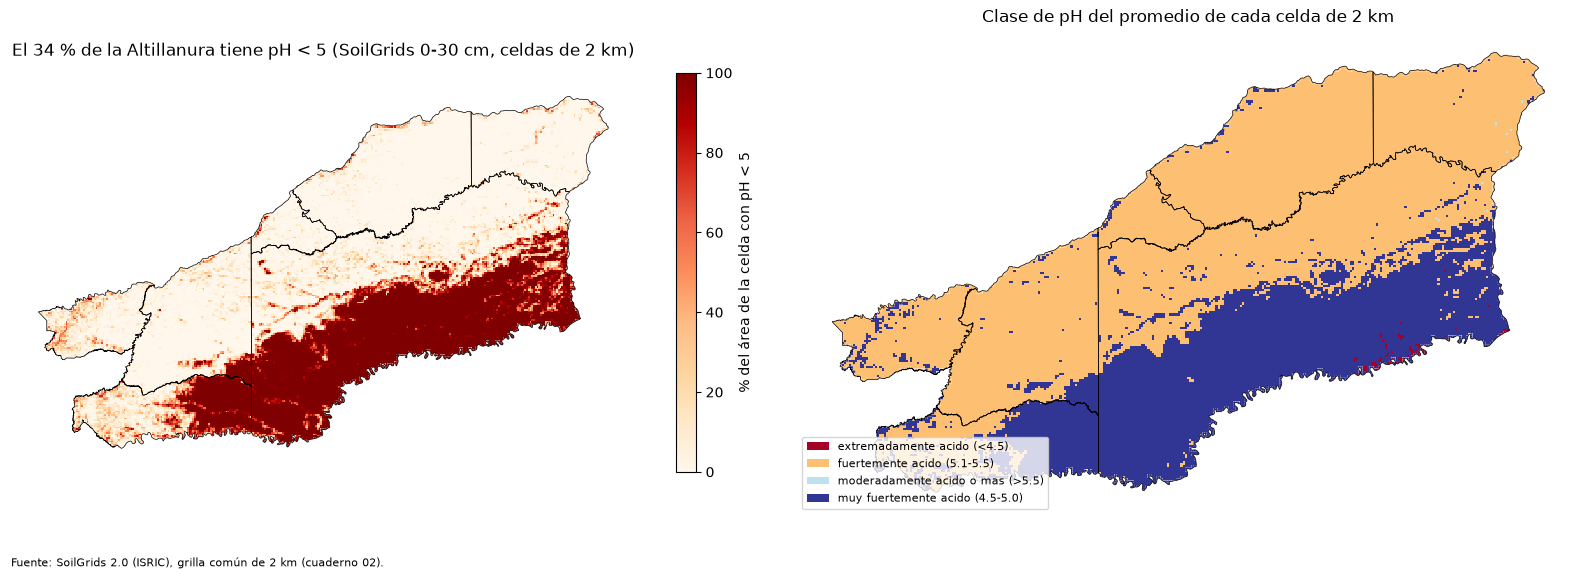

In [9]:
ok = suelo_celda["ph_kriging"].notna()
r_ph = suelo_celda.loc[ok, ["ph_medio", "ph_kriging"]].corr(method="spearman").iloc[0, 1]
r_cos = suelo_celda.loc[ok, ["cos_medio_gkg", "cos_kriging_gkg"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman celda SoilGrids vs. kriging: pH = {r_ph:.2f} | COS = {r_cos:.2f} ({ok.sum():,} celdas)")

celdas_geo = grilla[["id_celda", "geometry"]].merge(suelo_celda, on="id_celda")
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
celdas_geo.plot(ax=ax[0], column="pct_area_ph_menor_5", cmap="OrRd", legend=True,
                legend_kwds={"label": "% del área de la celda con pH < 5", "shrink": 0.7})
celdas_geo.plot(ax=ax[1], column="clase_ph", cmap="RdYlBu", legend=True,
                legend_kwds={"loc": "lower left", "fontsize": 8})
pct_total = np.average(suelo_municipio["pct_area_ph_menor_5"], weights=suelo_municipio["n_pixeles"])
ax[0].set_title(f"El {pct_total:.0f} % de la Altillanura tiene pH < 5 (SoilGrids 0-30 cm, celdas de 2 km)")
ax[1].set_title("Clase de pH del promedio de cada celda de 2 km")
for a_ in ax:
    mpios.to_crs(9377).boundary.plot(ax=a_, color="k", lw=0.5); a_.set_axis_off()
fig.text(0.01, 0.01, "Fuente: SoilGrids 2.0 (ISRIC), grilla común de 2 km (cuaderno 02).", fontsize=8)
plt.tight_layout()
plt.show()